# Análisis exploratorio de datos (EDA)
## Retrasos y cancelaciones de vuelos domésticos en EE. UU. (2016–2018)

**Base de datos:** *Airline Delay and Cancellation Data, 2009 – 2018* (Kaggle), construida a partir del reporte de puntualidad (On-Time Performance) del Departamento de Transporte de EE. UU. (BTS).
Se usan los archivos **2016.csv, 2017.csv y 2018.csv**, que juntos superan 1,5 GB.

**Objetivo del análisis:** identificar los factores (aerolínea, aeropuerto, mes, día, franja horaria y distancia) asociados a que un vuelo llegue con retraso significativo o se cancele.

**Unidad de análisis:** un vuelo doméstico programado (una fila).

**Variable objetivo:** `RETRASADO` = 1 si el vuelo llegó con 15 minutos o más de retraso (`ARR_DELAY` ≥ 15, criterio oficial del DOT), calculada solo para vuelos operados (ni cancelados ni desviados).

El notebook sigue el orden del EDA del proyecto de referencia:
1. Carga y primer vistazo
2. Limpieza de nulos (mapa de calor antes y después)
3. Columnas constantes y duplicados
4. Medidas estadísticas de las variables numéricas
5. Valores atípicos (boxplots antes y después de la corrección)
6. Variables categóricas
7. Variables booleanas
8. Relaciones entre variables (bivariado y multivariado)
9. Validación de hipótesis
10. Resumen de hallazgos para el informe

Cada gráfico se guarda numerado (**Gráfico N**) en la carpeta `salidas_eda`, junto con las tablas (**Tabla N**), para pegarlos directamente en el documento.

## 0. Librerías y configuración

In [1]:
from pathlib import Path
import json
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="pastel")

# ---------------- Parámetros ----------------
ANIOS = [2016, 2017, 2018]          # el proyecto exige > 1,5 GB: 3 años dan margen
FRACCION = 1.0                      # 1.0 = todos los registros. Si sale MemoryError, use 0.3
UMBRAL_RETRASO = 15                 # minutos (criterio oficial del DOT)
N_MUESTRA_GRAF = 200_000            # filas para gráficos pesados (dispersión, correlación)
SEED = 42

# Si el notebook está dentro de la carpeta de datos, se usa "."; si no, "Proyecto BD"
DATA_DIR = Path(".") if any(Path(".").glob("20*.csv")) else Path("Proyecto BD")
OUT_DIR = Path("salidas_eda")
OUT_DIR.mkdir(exist_ok=True)

# ---------------- Utilidades para numerar gráficos y tablas ----------------
_cont = {"grafico": 0, "tabla": 0}
HALLAZGOS = {}                      # se llena a lo largo del notebook

def _archivo(prefijo, n, titulo):
    """Nombre de archivo sin tildes ni espacios: grafico_01_valores_nulos..."""
    s = unicodedata.normalize("NFKD", titulo.lower()).encode("ascii", "ignore").decode()
    s = "".join(c if c.isalnum() else "_" for c in s).strip("_")
    return f"{prefijo}_{n:02d}_{s[:50]}"

def grafico(fig, titulo):
    """Numera, guarda y muestra el gráfico como 'Gráfico N. título'."""
    _cont["grafico"] += 1
    n = _cont["grafico"]
    fig.suptitle(f"Gráfico {n}. {titulo}", fontsize=13, fontweight="bold")
    fig.tight_layout()
    nombre = _archivo("grafico", n, titulo)
    fig.savefig(OUT_DIR / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

def tabla(df, titulo):
    """Numera, guarda en CSV y muestra la tabla como 'Tabla N. título'."""
    _cont["tabla"] += 1
    n = _cont["tabla"]
    print(f"Tabla {n}. {titulo}")
    nombre = _archivo("tabla", n, titulo)
    df.to_csv(OUT_DIR / f"{nombre}.csv")
    display(df)

def etiquetas_pct(ax, total=None):
    """Escribe el porcentaje encima de cada barra."""
    total = total or sum(p.get_height() for p in ax.patches)
    for p in ax.patches:
        ax.annotate(f"{p.get_height() / total:.2%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)

print("Carpeta de datos:", DATA_DIR.resolve())

Carpeta de datos: C:\Users\User\Desktop\Proyecto BD


## 1. Carga y primer vistazo

Se cargan los tres años con tipos de dato reducidos (`category`, `int16`, `float32`) para que quepan en memoria.
Primero se verifica que el conjunto supere el mínimo de 1,5 GB que pide el proyecto.

In [2]:
rutas = [DATA_DIR / f"{a}.csv" for a in ANIOS]
faltantes = [r.name for r in rutas if not r.exists()]
if faltantes:
    raise FileNotFoundError(f"No se encontraron {faltantes} en {DATA_DIR.resolve()}")

tamanos = pd.Series({r.name: r.stat().st_size / 1024**3 for r in rutas}, name="GB")
tamanos["TOTAL"] = tamanos.sum()
tabla(tamanos.to_frame().round(2), "Tamaño de los archivos utilizados (GB)")
HALLAZGOS["tamano_gb"] = round(float(tamanos["TOTAL"]), 2)
print("Cumple el mínimo de 1,5 GB:", tamanos["TOTAL"] > 1.5)

Tabla 1. Tamaño de los archivos utilizados (GB)


,GB
2016.csv,0.65
2017.csv,0.65
2018.csv,0.83
TOTAL,2.13


Cumple el mínimo de 1,5 GB: True


In [3]:
DTYPES = {
    "OP_CARRIER": "category", "OP_CARRIER_FL_NUM": "int32",
    "ORIGIN": "category", "DEST": "category",
    "CRS_DEP_TIME": "int16", "DEP_TIME": "float32", "DEP_DELAY": "float32",
    "TAXI_OUT": "float32", "WHEELS_OFF": "float32", "WHEELS_ON": "float32", "TAXI_IN": "float32",
    "CRS_ARR_TIME": "int16", "ARR_TIME": "float32", "ARR_DELAY": "float32",
    "CANCELLED": "float32", "CANCELLATION_CODE": "category", "DIVERTED": "float32",
    "CRS_ELAPSED_TIME": "float32", "ACTUAL_ELAPSED_TIME": "float32",
    "AIR_TIME": "float32", "DISTANCE": "float32",
    "CARRIER_DELAY": "float32", "WEATHER_DELAY": "float32", "NAS_DELAY": "float32",
    "SECURITY_DELAY": "float32", "LATE_AIRCRAFT_DELAY": "float32",
}

def leer_anio(ruta):
    if FRACCION >= 1:
        return pd.read_csv(ruta, dtype=DTYPES, parse_dates=["FL_DATE"])
    partes = [ch.sample(frac=FRACCION, random_state=SEED)
              for ch in pd.read_csv(ruta, dtype=DTYPES, parse_dates=["FL_DATE"], chunksize=1_000_000)]
    return pd.concat(partes, ignore_index=True)

frames = []
for r in rutas:
    d = leer_anio(r)
    print(f"{r.name}: {len(d):,} filas")
    frames.append(d)
df = pd.concat(frames, ignore_index=True)
del frames

# Unificar categorías tras el concat
for c in ["OP_CARRIER", "ORIGIN", "DEST", "CANCELLATION_CODE"]:
    df[c] = df[c].astype("category")

print(f"\nTotal: {df.shape[0]:,} filas y {df.shape[1]} columnas")
print(f"Memoria en uso: {df.memory_usage(deep=True).sum() / 1024**3:.2f} GB")
HALLAZGOS["filas"] = int(df.shape[0])
HALLAZGOS["columnas"] = int(df.shape[1])
df.head()

2016.csv: 5,617,658 filas
2017.csv: 5,674,621 filas
2018.csv: 7,213,446 filas

Total: 18,505,725 filas y 28 columnas
Memoria en uso: 1.83 GB


,FL_DATE,OP_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,Unnamed: 27
0,2016-01-01,DL,1248,DTW,LAX,1935,"1,935.00",0.00,23.00,"1,958.00","2,107.00",13.00,2144,"2,120.00",-24.00,0.00,NaN,0.00,309.00,285.00,249.00,"1,979.00",NaN,NaN,NaN,NaN,NaN,NaN
1,2016-01-01,DL,1251,ATL,GRR,2125,"2,130.00",5.00,13.00,"2,143.00","2,315.00",4.00,2321,"2,319.00",-2.00,0.00,NaN,0.00,116.00,109.00,92.00,640.00,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-01-01,DL,1254,LAX,ATL,2255,"2,256.00",1.00,19.00,"2,315.00",542.00,5.00,600,547.00,-13.00,0.00,NaN,0.00,245.00,231.00,207.00,"1,947.00",NaN,NaN,NaN,NaN,NaN,NaN
3,2016-01-01,DL,1255,SLC,ATL,1656,"1,700.00",4.00,12.00,"1,712.00","2,205.00",8.00,2229,"2,213.00",-16.00,0.00,NaN,0.00,213.00,193.00,173.00,"1,590.00",NaN,NaN,NaN,NaN,NaN,NaN
4,2016-01-01,DL,1256,BZN,MSP,900,"1,012.00",72.00,63.00,"1,115.00","1,416.00",4.00,1216,"1,420.00",124.00,0.00,NaN,0.00,136.00,188.00,121.00,874.00,72.00,0.00,52.00,0.00,0.00,NaN


In [4]:
# Tipos de dato por columna (equivalente a df.info())
tipos = pd.DataFrame({"tipo": df.dtypes.astype(str), "valores_unicos": df.nunique()})
tabla(tipos, "Tipos de dato y valores únicos por columna")
print(tipos["tipo"].value_counts())

Tabla 2. Tipos de dato y valores únicos por columna


,tipo,valores_unicos
FL_DATE,datetime64[us],1096
OP_CARRIER,category,18
OP_CARRIER_FL_NUM,int32,7119
ORIGIN,category,362
DEST,category,360
CRS_DEP_TIME,int16,1420
DEP_TIME,float32,1440
DEP_DELAY,float32,1644
TAXI_OUT,float32,185
WHEELS_OFF,float32,1440


tipo
float32           19
category           4
int16              2
datetime64[us]     1
int32              1
float64            1
Name: count, dtype: int64


## 2. Limpieza de valores nulos

En el proyecto de referencia se eliminaron las columnas con más del 80 % de nulos y el resto se imputó con la moda.
**En esta base esa regla no se puede aplicar a ciegas**, porque casi todos los nulos son *estructurales*, es decir, tienen una razón operativa:

| Columnas | Por qué son nulas | Tratamiento |
|---|---|---|
| `Unnamed: 27` | Columna vacía creada por una coma al final de cada línea | Se elimina |
| `CANCELLATION_CODE` | Solo existe si el vuelo se canceló | Se reemplaza el nulo por "No cancelado" |
| `CARRIER_DELAY` … `LATE_AIRCRAFT_DELAY` | El DOT solo registra la causa si el retraso es ≥ 15 min | Se llenan con 0 en vuelos operados con retraso < 15 min |
| `DEP_TIME`, `DEP_DELAY`, `TAXI_OUT`, `WHEELS_OFF` | El vuelo se canceló antes de salir | Se dejan nulos: imputar 0 o la moda crearía vuelos "puntuales" que nunca volaron |
| `ARR_TIME`, `ARR_DELAY`, `AIR_TIME`, … | El vuelo se canceló o se desvió | Se dejan nulos; la variable objetivo solo se calcula en vuelos operados |

Las columnas de causa superan el 80 % de nulos, pero **son las más importantes para el diagnóstico gerencial**; eliminarlas sería un error.

Tabla 3. Cantidad y porcentaje de nulos por columna (antes de la limpieza)


,nulos,porcentaje
Unnamed: 27,18505725,100.00
CANCELLATION_CODE,18240587,98.57
NAS_DELAY,15159303,81.92
LATE_AIRCRAFT_DELAY,15159303,81.92
SECURITY_DELAY,15159303,81.92
WEATHER_DELAY,15159303,81.92
CARRIER_DELAY,15159303,81.92
ARR_DELAY,311764,1.68
ACTUAL_ELAPSED_TIME,309166,1.67
AIR_TIME,309166,1.67


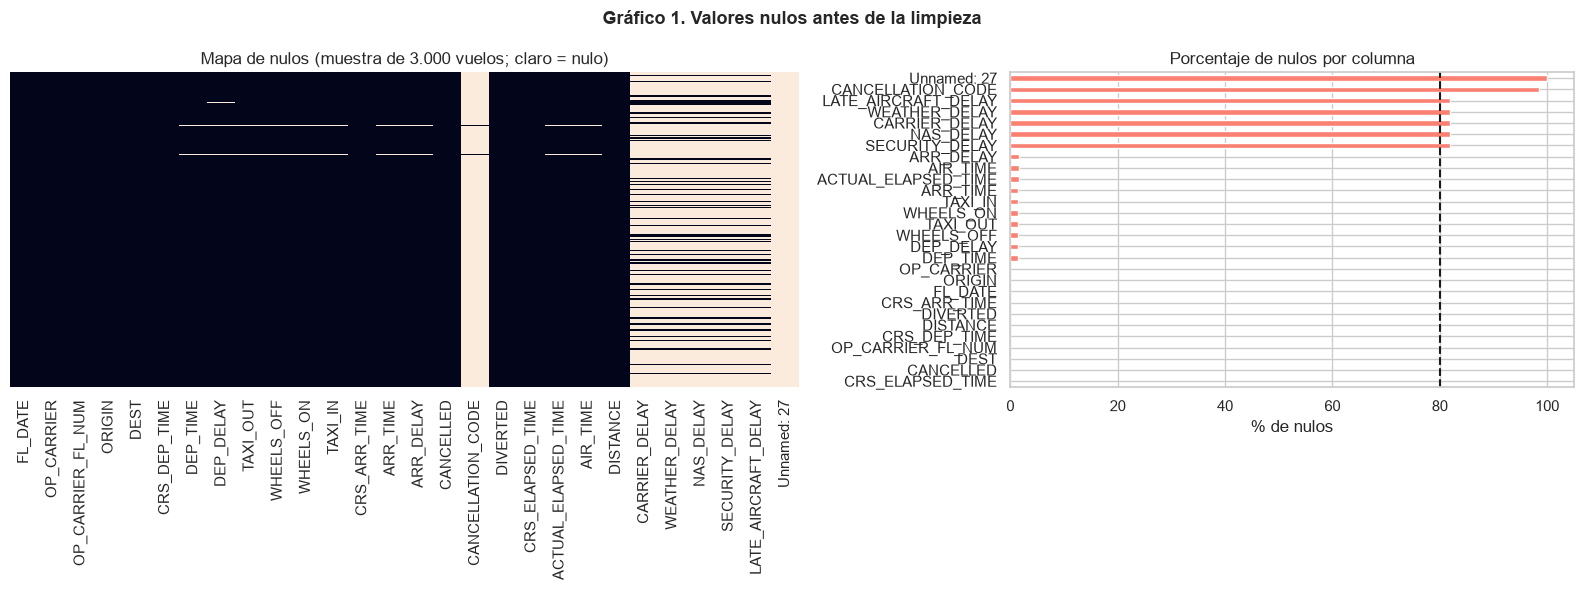

In [5]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
}).sort_values("porcentaje", ascending=False)
tabla(nulos, "Cantidad y porcentaje de nulos por columna (antes de la limpieza)")

fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.4, 1]})
muestra_nulos = df.sample(min(3000, len(df)), random_state=SEED).isna()
sns.heatmap(muestra_nulos, cbar=False, yticklabels=False, cmap="rocket", ax=ax[0])
ax[0].set_title("Mapa de nulos (muestra de 3.000 vuelos; claro = nulo)")
nulos["porcentaje"].sort_values().plot.barh(ax=ax[1], color="salmon")
ax[1].set_xlabel("% de nulos"); ax[1].axvline(80, ls="--", c="k")
ax[1].set_title("Porcentaje de nulos por columna")
grafico(fig, "Valores nulos antes de la limpieza")

In [6]:
CAUSAS = ["CARRIER_DELAY", "WEATHER_DELAY", "NAS_DELAY", "SECURITY_DELAY", "LATE_AIRCRAFT_DELAY"]

# Verificación de que los nulos son estructurales (deben dar 0 o casi 0)
cancelado = df["CANCELLED"] == 1
desviado = df["DIVERTED"] == 1
operado = ~cancelado & ~desviado
chequeo = pd.Series({
    "DEP_DELAY nulo en vuelos NO cancelados": int((~cancelado & df["DEP_DELAY"].isna()).sum()),
    "ARR_DELAY nulo en vuelos operados": int((operado & df["ARR_DELAY"].isna()).sum()),
    "Causas nulas en vuelos con retraso >= 15": int((operado & (df["ARR_DELAY"] >= UMBRAL_RETRASO)
                                                   & df[CAUSAS].isna().any(axis=1)).sum()),
    "CANCELLATION_CODE nulo en cancelados": int((cancelado & df["CANCELLATION_CODE"].isna()).sum()),
}, name="registros")
tabla(chequeo.to_frame(), "Nulos que NO se explican por la lógica operativa")

Tabla 4. Nulos que NO se explican por la lógica operativa


,registros
DEP_DELAY nulo en vuelos NO cancelados,4744
ARR_DELAY nulo en vuelos operados,2600
Causas nulas en vuelos con retraso >= 15,1
CANCELLATION_CODE nulo en cancelados,0


Columnas eliminadas por estar 100 % vacías: ['Unnamed: 27']
Vuelos operados con nulos inexplicables eliminados: 7,189


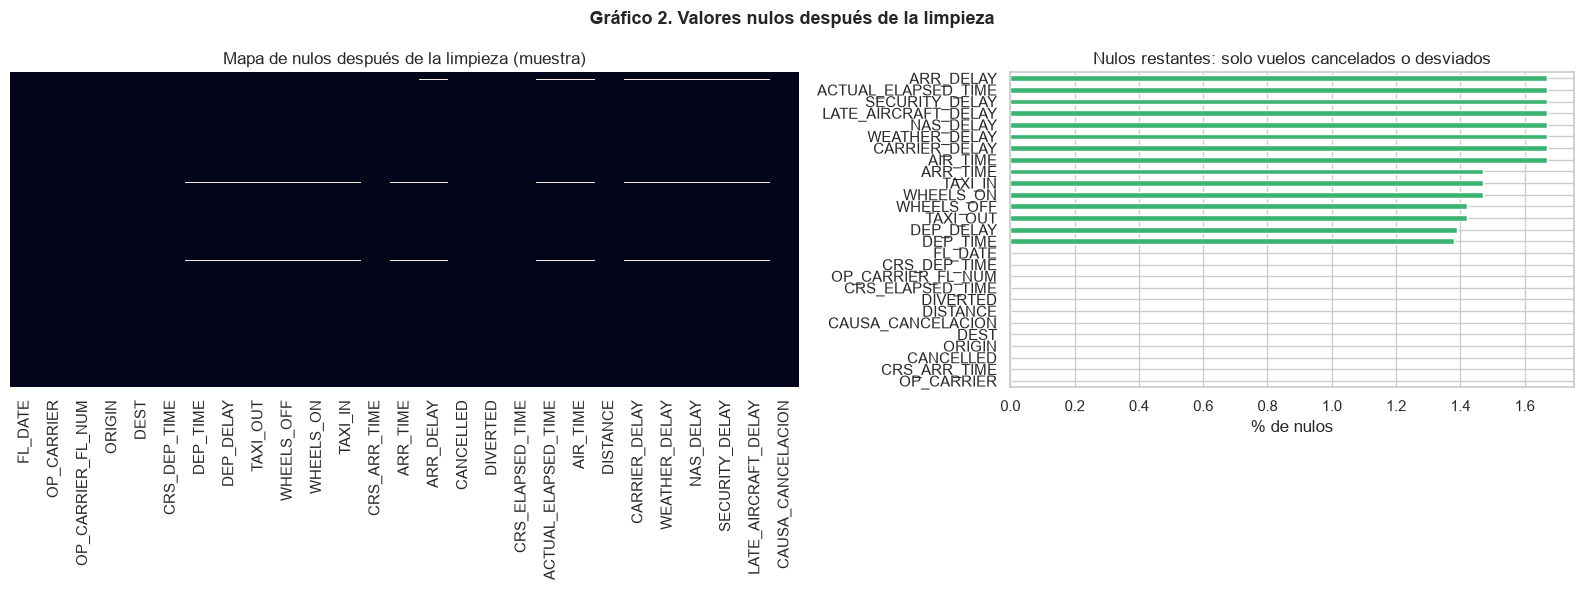

In [7]:
# 1) Eliminar la columna vacía
cols_vacias = [c for c in df.columns if df[c].isna().all()]
df = df.drop(columns=cols_vacias)
print("Columnas eliminadas por estar 100 % vacías:", cols_vacias)

# 2) Causa de cancelación: el nulo significa "no se canceló"
mapa_cancel = {"A": "Aerolínea", "B": "Clima", "C": "Sistema aéreo (NAS)", "D": "Seguridad"}
df["CAUSA_CANCELACION"] = (df["CANCELLATION_CODE"].astype("object").map(mapa_cancel)
                           .fillna("No cancelado").astype("category"))
df = df.drop(columns=["CANCELLATION_CODE"])

# 3) Causas de retraso: 0 para vuelos operados que no llegaron a 15 min de retraso
df["CANCELLED"] = df["CANCELLED"].fillna(0).astype("int8")
df["DIVERTED"] = df["DIVERTED"].fillna(0).astype("int8")
operado = (df["CANCELLED"] == 0) & (df["DIVERTED"] == 0)
m = operado & (df["ARR_DELAY"] < UMBRAL_RETRASO)
df.loc[m, CAUSAS] = df.loc[m, CAUSAS].fillna(0)

# 4) Nulos inexplicables en vuelos operados -> se eliminan (son muy pocos)
inexplicables = operado & df[["DEP_DELAY", "ARR_DELAY", "AIR_TIME"]].isna().any(axis=1)
print(f"Vuelos operados con nulos inexplicables eliminados: {inexplicables.sum():,}")
df = df.loc[~inexplicables].reset_index(drop=True)

nulos_despues = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.4, 1]})
sns.heatmap(df.sample(min(3000, len(df)), random_state=SEED).isna(), cbar=False,
            yticklabels=False, cmap="rocket", ax=ax[0])
ax[0].set_title("Mapa de nulos después de la limpieza (muestra)")
nulos_despues.sort_values().plot.barh(ax=ax[1], color="mediumseagreen")
ax[1].set_xlabel("% de nulos")
ax[1].set_title("Nulos restantes: solo vuelos cancelados o desviados")
grafico(fig, "Valores nulos después de la limpieza")

## 3. Columnas constantes y duplicados

Igual que en el proyecto de referencia (donde se eliminaron `Agency` y `HAZMAT`), se buscan columnas con un único valor, que no aportan información.
Luego se revisan dos tipos de duplicados:
- **Exactos:** la fila completa se repite (error de carga).
- **Lógicos:** misma fecha, aerolínea, número de vuelo, origen, destino y hora programada. Un vuelo no puede salir dos veces igual el mismo día.

In [8]:
constantes = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("Columnas constantes:", constantes if constantes else "ninguna")
df = df.drop(columns=constantes)

LLAVE = ["FL_DATE", "OP_CARRIER", "OP_CARRIER_FL_NUM", "ORIGIN", "DEST", "CRS_DEP_TIME"]
dup_exactos = int(df.duplicated().sum())
df = df.drop_duplicates()
dup_logicos = int(df.duplicated(subset=LLAVE).sum())
df = df.drop_duplicates(subset=LLAVE).reset_index(drop=True)
print(f"Duplicados exactos eliminados: {dup_exactos:,}")
print(f"Duplicados lógicos eliminados: {dup_logicos:,}")
HALLAZGOS["duplicados_eliminados"] = dup_exactos + dup_logicos

Columnas constantes: ninguna
Duplicados exactos eliminados: 0
Duplicados lógicos eliminados: 11


In [9]:
# Verificación de meses completos (en 2009.csv hay un mes duplicado y otro casi vacío)
vuelos_mes = df.groupby([df["FL_DATE"].dt.year.rename("AÑO"), df["FL_DATE"].dt.month.rename("MES")]).size().unstack()
tabla(vuelos_mes, "Vuelos por año y mes (para detectar meses faltantes o duplicados)")

Tabla 5. Vuelos por año y mes (para detectar meses faltantes o duplicados)


MES,1,2,3,4,5,6,7,8,9,10,11,12
AÑO,,,,,,,,,,,,
2016,445827,423889,479122,461630,479358,487637,502457,498347,454878,472626,450938,460949
2017,450017,410517,488597,468328,486482,494266,509069,510451,458727,479797,454161,464205
2018,569439,520052,611017,595100,615562,625100,644340,643771,585748,616101,586178,593842


### Variables derivadas

Se construyen la variable objetivo y las variables de calendario a partir de la fecha y la hora programada.
Las horas vienen como enteros en formato *hhmm* (por ejemplo 1305 = 13:05; 2400 = medianoche).

In [10]:
df["AÑO"] = df["FL_DATE"].dt.year.astype("int16")
df["MES"] = df["FL_DATE"].dt.month.astype("int8")
df["DIA_SEMANA"] = df["FL_DATE"].dt.dayofweek.astype("int8")              # 0 = lunes
df["HORA_SALIDA"] = ((df["CRS_DEP_TIME"] // 100) % 24).astype("int8")      # hora programada
df["OPERADO"] = ((df["CANCELLED"] == 0) & (df["DIVERTED"] == 0)).astype("int8")
df["RETRASADO"] = np.where(df["OPERADO"] == 1,
                           (df["ARR_DELAY"] >= UMBRAL_RETRASO).astype("float32"), np.nan).astype("float32")
df["SEG_DISTANCIA"] = pd.cut(df["DISTANCE"], [0, 500, 1500, np.inf],
                             labels=["Corto (<500 mi)", "Medio (500-1500 mi)", "Largo (>1500 mi)"])
NOMBRE_DIA = {0: "Lun", 1: "Mar", 2: "Mié", 3: "Jue", 4: "Vie", 5: "Sáb", 6: "Dom"}
op = df[df["OPERADO"] == 1]                       # vista de vuelos operados
print(f"Vuelos operados: {len(op):,}  |  Cancelados: {df['CANCELLED'].sum():,}  |  Desviados: {df['DIVERTED'].sum():,}")

C:\Users\User\AppData\Local\Temp\ipykernel_12608\1018141409.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["DIA_SEMANA"] = df["FL_DATE"].dt.dayofweek.astype("int8")              # 0 = lunes


Vuelos operados: 18,189,367  |  Cancelados: 265,133  |  Desviados: 44,040


## 4. Medidas estadísticas de las variables numéricas

Se calculan conteo, media, desviación estándar, mínimo, cuartiles y máximo, más los percentiles 90, 95 y 99, porque los retrasos tienen una cola derecha muy larga y la media sola engaña.

In [11]:
NUM = ["DEP_DELAY", "ARR_DELAY", "TAXI_OUT", "TAXI_IN", "AIR_TIME", "CRS_ELAPSED_TIME",
       "ACTUAL_ELAPSED_TIME", "DISTANCE"] + CAUSAS
desc = df[NUM].describe(percentiles=[.25, .5, .75, .9, .95, .99]).T
desc["asimetria"] = df[NUM].skew()
tabla(desc.round(2), "Medidas estadísticas de las variables numéricas")

HALLAZGOS["arr_delay_media"] = round(float(op["ARR_DELAY"].mean()), 1)
HALLAZGOS["arr_delay_mediana"] = round(float(op["ARR_DELAY"].median()), 1)
HALLAZGOS["arr_delay_p95"] = round(float(op["ARR_DELAY"].quantile(.95)), 1)
print(f"ARR_DELAY: media {HALLAZGOS['arr_delay_media']} min, mediana {HALLAZGOS['arr_delay_mediana']} min, "
      f"p95 {HALLAZGOS['arr_delay_p95']} min.")
print("Que la media sea mayor que la mediana confirma una distribución asimétrica a la derecha.")

Tabla 6. Medidas estadísticas de las variables numéricas


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,asimetria
DEP_DELAY,"18,242,221.00",9.58,43.05,-234.00,-5.00,-2.00,6.00,35.00,70.00,181.00,"2,755.00",9.55
ARR_DELAY,"18,189,367.00",4.36,45.12,-238.00,-14.00,-6.00,7.00,35.00,70.00,180.00,"2,692.00",8.37
TAXI_OUT,"18,235,137.00",16.84,9.44,0.00,11.00,14.00,20.00,27.00,33.00,53.00,196.00,3.32
TAXI_IN,"18,226,768.00",7.53,5.91,0.00,4.00,6.00,9.00,13.00,17.00,31.00,414.00,5.39
AIR_TIME,"18,189,367.00",114.88,72.89,4.00,61.00,96.00,145.00,219.00,276.00,338.00,723.00,1.36
CRS_ELAPSED_TIME,"18,498,502.00",144.24,75.51,-99.00,89.00,125.00,175.00,252.00,310.00,379.00,718.00,1.34
ACTUAL_ELAPSED_TIME,"18,189,367.00",139.24,75.05,14.00,84.00,120.00,171.00,246.00,303.00,371.00,784.00,1.34
DISTANCE,"18,498,525.00",832.72,613.45,25.00,374.00,666.00,"1,069.00","1,726.00","2,248.00","2,588.00","4,983.00",1.39
CARRIER_DELAY,"18,189,366.00",3.65,26.66,0.00,0.00,0.00,0.00,0.00,15.00,85.00,"2,142.00",21.07
WEATHER_DELAY,"18,189,366.00",0.57,11.23,0.00,0.00,0.00,0.00,0.00,0.00,1.00,"2,692.00",49.27


ARR_DELAY: media 4.4 min, mediana -6.0 min, p95 70.0 min.
Que la media sea mayor que la mediana confirma una distribución asimétrica a la derecha.


## 5. Valores atípicos

Se separan dos tipos de atípicos:
- **Imposibles (se eliminan):** tiempo en el aire ≤ 0 o mayor al tiempo total del vuelo, velocidad media mayor a 700 mph o menor a 100 mph, o salir más de 90 minutos antes de lo programado.
- **Extremos reales (se conservan):** retrasos de 10 o 20 horas existen (vuelos reprogramados para el día siguiente) y son los que más le cuestan a la aerolínea. Se marcan con `RETRASO_EXTREMO` en lugar de borrarse.

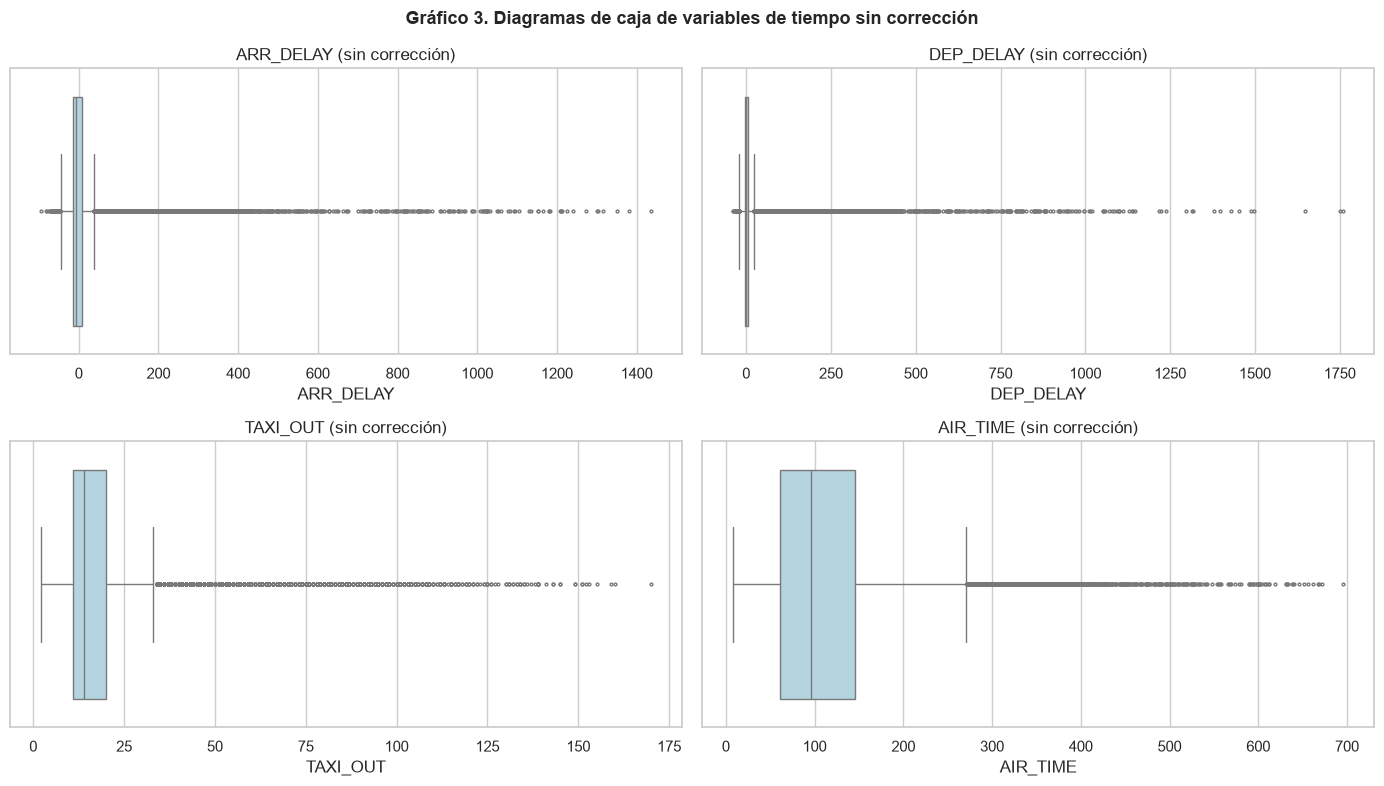

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), ["ARR_DELAY", "DEP_DELAY", "TAXI_OUT", "AIR_TIME"]):
    sns.boxplot(x=df[col].dropna().sample(min(N_MUESTRA_GRAF, df[col].notna().sum()), random_state=SEED),
                ax=ax, color="lightblue", flierprops={"markersize": 2})
    ax.set_title(f"{col} (sin corrección)")
grafico(fig, "Diagramas de caja de variables de tiempo sin corrección")

In [13]:
velocidad = df["DISTANCE"] / df["AIR_TIME"] * 60
reglas = {
    "AIR_TIME <= 0": df["AIR_TIME"] <= 0,
    "CRS_ELAPSED_TIME <= 0 (duración programada negativa)": df["CRS_ELAPSED_TIME"] <= 0,
    "AIR_TIME > ACTUAL_ELAPSED_TIME": df["AIR_TIME"] > df["ACTUAL_ELAPSED_TIME"],
    "Velocidad > 700 mph o < 100 mph": (velocidad > 700) | (velocidad < 100),
    "DEP_DELAY < -90 min": df["DEP_DELAY"] < -90,
    "Hora programada inválida (min >= 60)": (df["CRS_DEP_TIME"] % 100) >= 60,
}
conteo = pd.Series({k: int(v.sum()) for k, v in reglas.items()}, name="registros")
tabla(conteo.to_frame(), "Registros con valores imposibles")
imposible = np.logical_or.reduce(list(reglas.values()))   # NaN cuenta como False: los cancelados se conservan
df = df.loc[~imposible].reset_index(drop=True)
print(f"Eliminados: {imposible.sum():,} ({imposible.mean():.3%} del total)")

df["RETRASO_EXTREMO"] = (df["ARR_DELAY"] > 720).astype("int8")   # más de 12 horas
print(f"Retrasos extremos (> 12 h) conservados y marcados: {df['RETRASO_EXTREMO'].sum():,}")
op = df[df["OPERADO"] == 1]

Tabla 7. Registros con valores imposibles


,registros
AIR_TIME <= 0,0
CRS_ELAPSED_TIME <= 0 (duración programada negativa),5
AIR_TIME > ACTUAL_ELAPSED_TIME,0
Velocidad > 700 mph o < 100 mph,434
DEP_DELAY < -90 min,22
Hora programada inválida (min >= 60),0


Eliminados: 461 (0.002% del total)
Retrasos extremos (> 12 h) conservados y marcados: 8,538


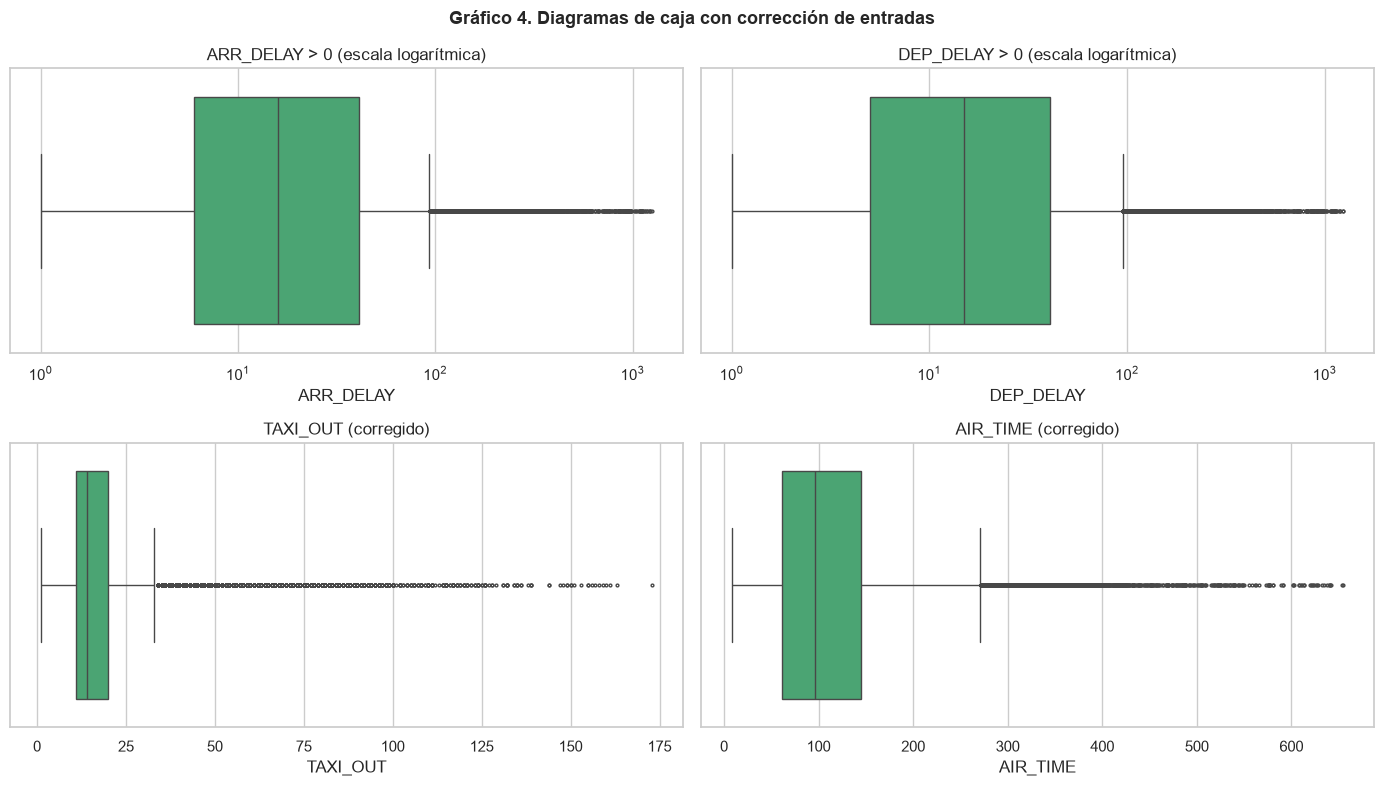

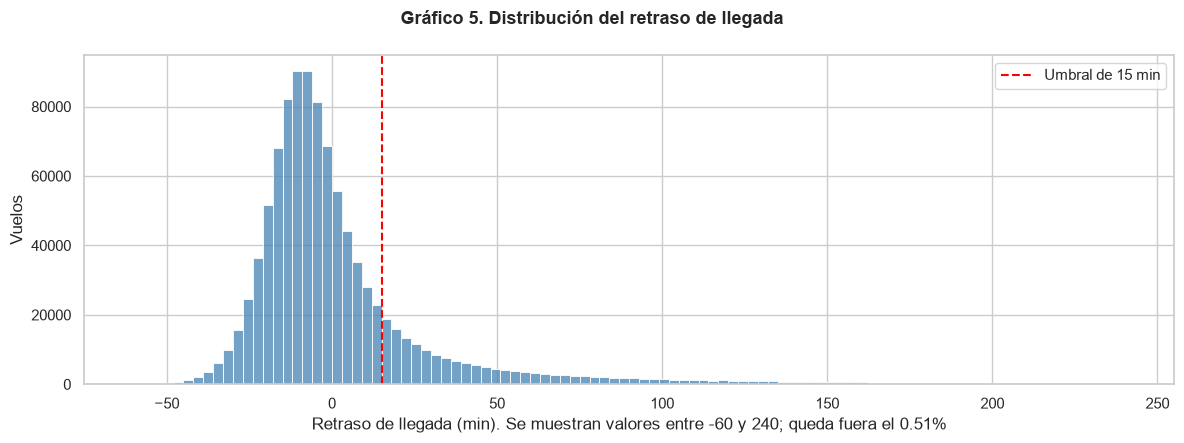

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, col in zip(axes.ravel(), ["ARR_DELAY", "DEP_DELAY", "TAXI_OUT", "AIR_TIME"]):
    s = op[col].dropna().sample(min(N_MUESTRA_GRAF, len(op)), random_state=SEED)
    if col in ("ARR_DELAY", "DEP_DELAY"):
        sns.boxplot(x=s[s > 0], ax=ax, color="mediumseagreen", flierprops={"markersize": 2})
        ax.set_xscale("log"); ax.set_title(f"{col} > 0 (escala logarítmica)")
    else:
        sns.boxplot(x=s, ax=ax, color="mediumseagreen", flierprops={"markersize": 2})
        ax.set_title(f"{col} (corregido)")
grafico(fig, "Diagramas de caja con corrección de entradas")

fig, ax = plt.subplots(figsize=(12, 4.5))
rango = op["ARR_DELAY"].between(-60, 240)
sns.histplot(op.loc[rango, "ARR_DELAY"].sample(min(N_MUESTRA_GRAF * 5, int(rango.sum())), random_state=SEED),
             bins=100, ax=ax, color="steelblue")
ax.axvline(UMBRAL_RETRASO, ls="--", c="red", label="Umbral de 15 min")
ax.set(xlabel=f"Retraso de llegada (min). Se muestran valores entre -60 y 240; queda fuera el {1 - rango.mean():.2%}",
       ylabel="Vuelos"); ax.legend()
grafico(fig, "Distribución del retraso de llegada")

## 6. Variables categóricas

Equivalente a `describe(include=['object'])` del proyecto de referencia: cantidad de registros, valores únicos, moda y frecuencia de la moda.
Luego se grafica la distribución por hora (como la "Distribución de horas de multa"), día, mes, aerolínea, aeropuerto y causa de cancelación.

In [15]:
CAT = ["OP_CARRIER", "ORIGIN", "DEST", "CAUSA_CANCELACION", "SEG_DISTANCIA"]
tabla(df[CAT].astype("object").describe().T, "Resumen de las variables categóricas")

Tabla 8. Resumen de las variables categóricas


,count,unique,top,freq
OP_CARRIER,18498064,18,WN,3981393
ORIGIN,18498064,361,ATL,1138137
DEST,18498064,360,ATL,1138137
CAUSA_CANCELACION,18498064,5,No cancelado,18232931
SEG_DISTANCIA,18498064,3,Medio (500-1500 mi),9203574


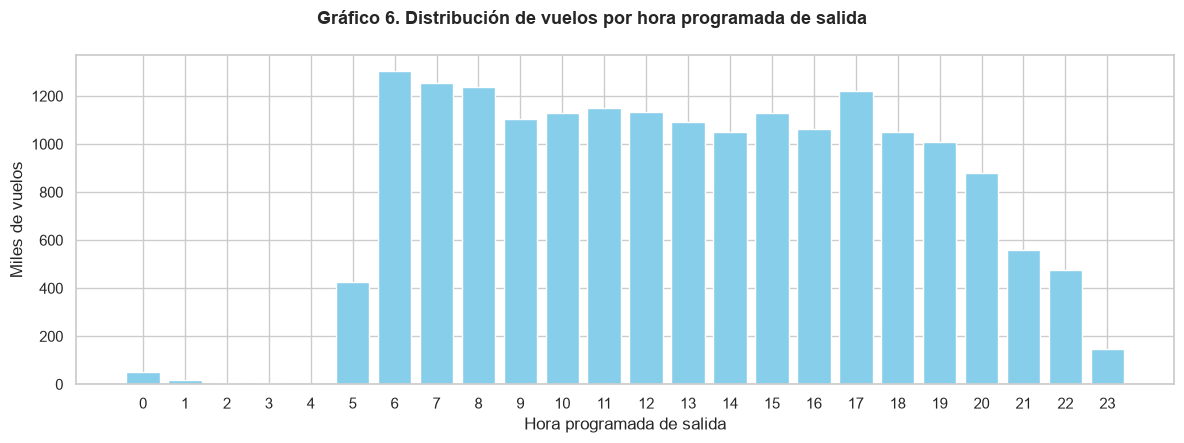

La hora con más vuelos programados es las 6:00 (1,305,431 vuelos); la de menos, las 4:00.


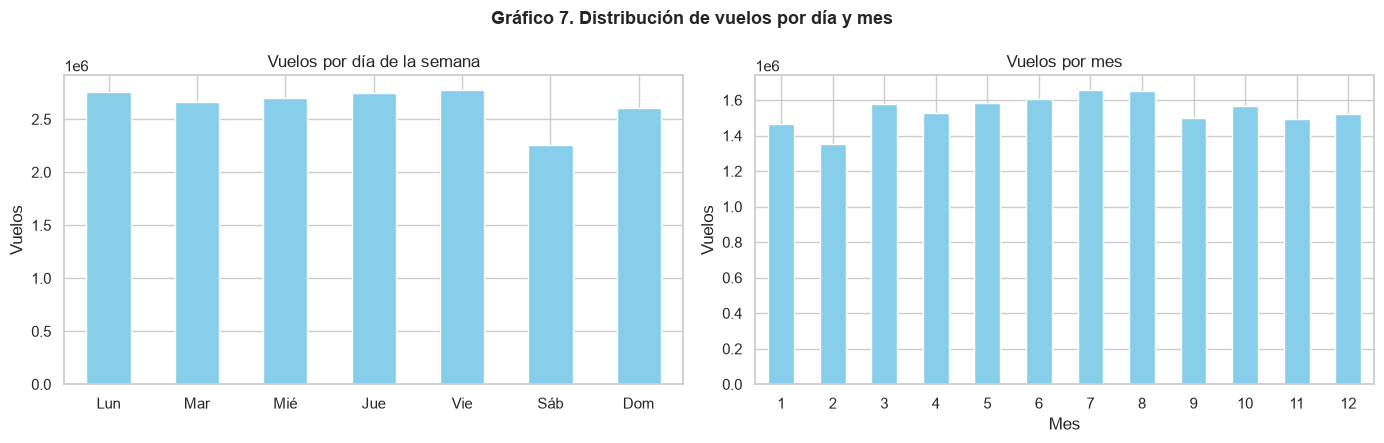

In [16]:
fig, ax = plt.subplots(figsize=(12, 4.5))
por_hora = df["HORA_SALIDA"].value_counts().sort_index()
ax.bar(por_hora.index, por_hora.values / 1e3, color="skyblue")
ax.set(xlabel="Hora programada de salida", ylabel="Miles de vuelos", xticks=range(24))
grafico(fig, "Distribución de vuelos por hora programada de salida")
HALLAZGOS["hora_pico_vuelos"] = int(por_hora.idxmax())
print(f"La hora con más vuelos programados es las {por_hora.idxmax()}:00 ({por_hora.max():,} vuelos); "
      f"la de menos, las {por_hora.idxmin()}:00.")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
df["DIA_SEMANA"].map(NOMBRE_DIA).value_counts().reindex(NOMBRE_DIA.values()).plot.bar(ax=ax[0], color="skyblue", rot=0)
ax[0].set(title="Vuelos por día de la semana", ylabel="Vuelos", xlabel="")
df["MES"].value_counts().sort_index().plot.bar(ax=ax[1], color="skyblue", rot=0)
ax[1].set(title="Vuelos por mes", ylabel="Vuelos", xlabel="Mes")
grafico(fig, "Distribución de vuelos por día y mes")

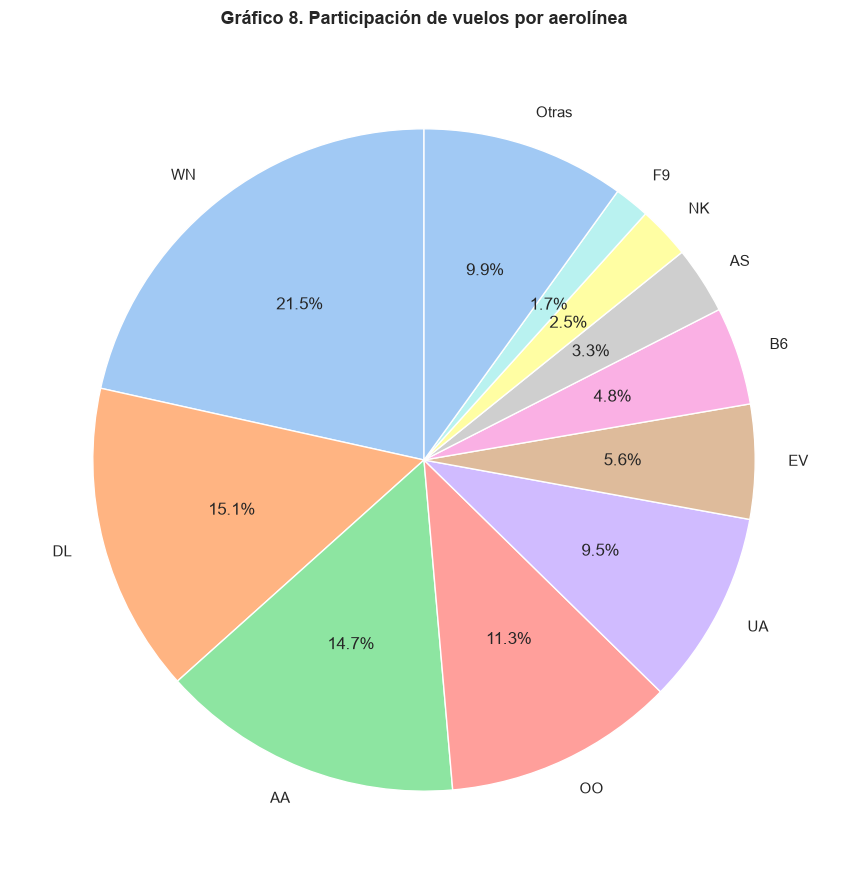

La aerolínea con más vuelos es WN (21.5% del total). Las 3 primeras concentran el 51.4%.


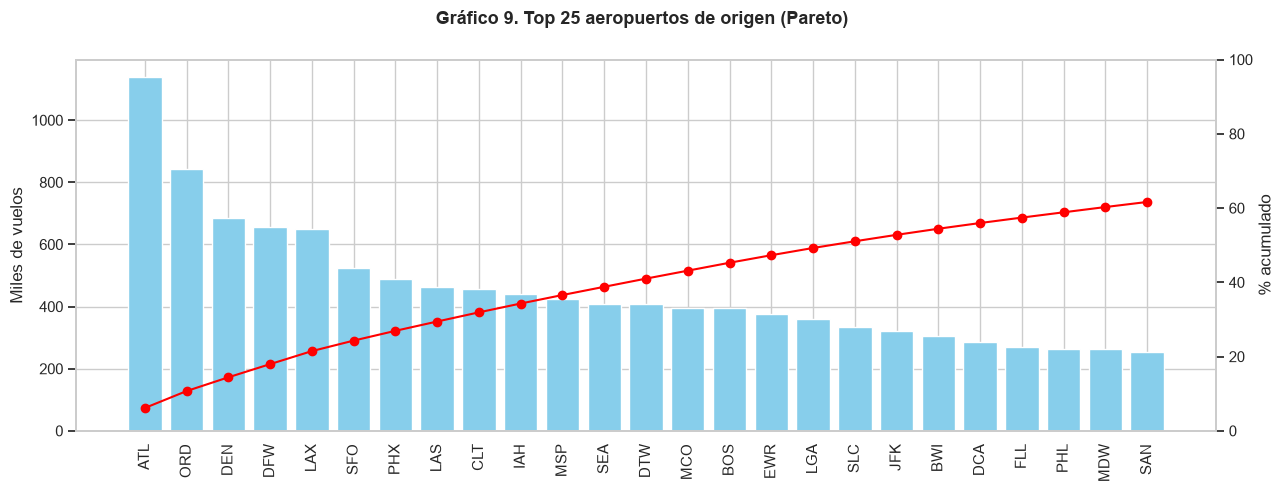

Hay 362 aeropuertos de origen; los 25 principales concentran el 61.6% de los vuelos.


In [17]:
aer = df["OP_CARRIER"].value_counts()
top = pd.concat([aer.head(10), pd.Series({"Otras": aer.iloc[10:].sum()})])
fig, ax = plt.subplots(figsize=(9, 9))
ax.pie(top, labels=top.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("pastel", len(top)))
grafico(fig, "Participación de vuelos por aerolínea")
HALLAZGOS["aerolinea_mas_vuelos"] = str(aer.index[0])
print(f"La aerolínea con más vuelos es {aer.index[0]} ({aer.iloc[0] / aer.sum():.1%} del total). "
      f"Las 3 primeras concentran el {aer.head(3).sum() / aer.sum():.1%}.")

ori = df["ORIGIN"].value_counts()
acum = ori.cumsum() / ori.sum() * 100
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(ori.index[:25].astype(str), ori.values[:25] / 1e3, color="skyblue")
ax.set_ylabel("Miles de vuelos"); ax.tick_params(axis="x", rotation=90)
ax2 = ax.twinx(); ax2.plot(ori.index[:25].astype(str), acum.values[:25], color="red", marker="o")
ax2.set_ylabel("% acumulado"); ax2.set_ylim(0, 100); ax2.grid(False)
grafico(fig, "Top 25 aeropuertos de origen (Pareto)")
HALLAZGOS["top25_aeropuertos_pct"] = round(float(acum.iloc[24]), 1)
print(f"Hay {ori.size} aeropuertos de origen; los 25 principales concentran el {acum.iloc[24]:.1f}% de los vuelos.")

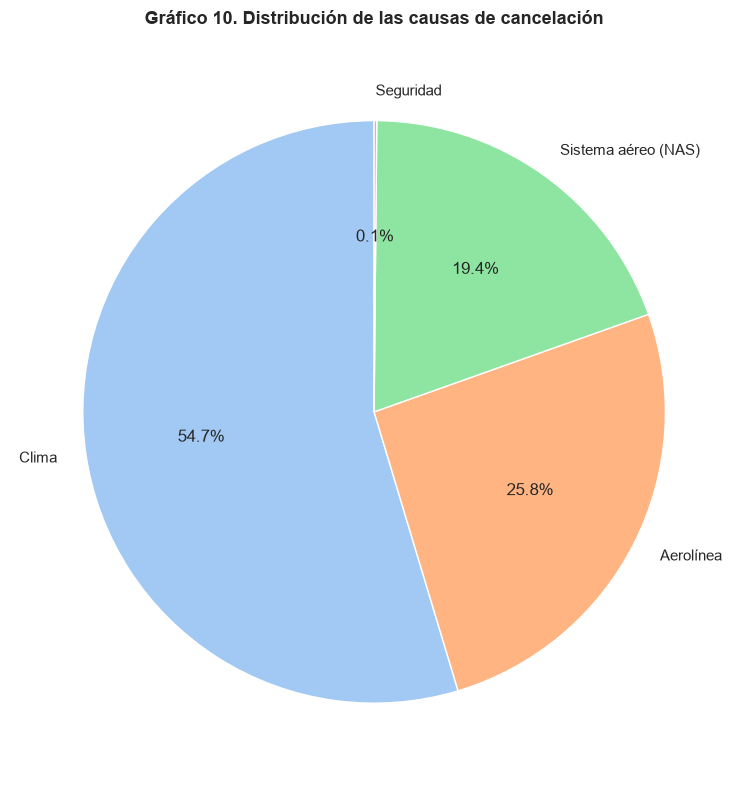

La principal causa de cancelación es 'Clima' (54.7%).


In [18]:
canc = df.loc[df["CANCELLED"] == 1, "CAUSA_CANCELACION"].value_counts()
canc = canc[canc > 0]                      # quita categorías sin registros (p. ej. "No cancelado")
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(canc, labels=canc.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("pastel", len(canc)))
grafico(fig, "Distribución de las causas de cancelación")
HALLAZGOS["causa_cancelacion_principal"] = str(canc.index[0])
print(f"La principal causa de cancelación es '{canc.index[0]}' ({canc.iloc[0] / canc.sum():.1%}).")

## 7. Variables booleanas

Igual que en el proyecto de referencia, las variables sí/no se muestran en gráficos de barras con el porcentaje de cada respuesta.

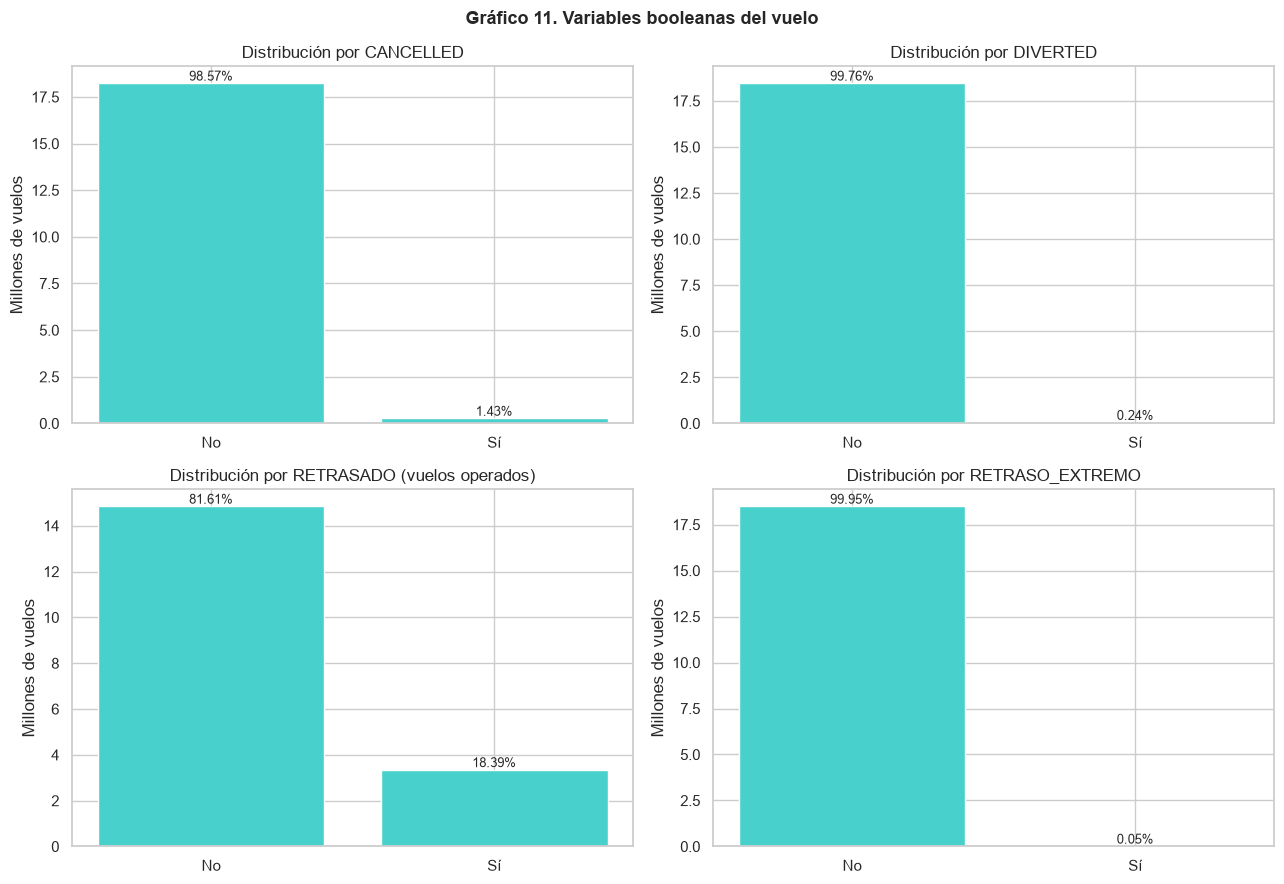

El 18.39% de los vuelos operados llegó con 15 min o más de retraso; se canceló el 1.43% y se desvió el 0.24%.


In [19]:
BOOL = {"CANCELLED": df["CANCELLED"], "DIVERTED": df["DIVERTED"],
        "RETRASADO (vuelos operados)": op["RETRASADO"], "RETRASO_EXTREMO": df["RETRASO_EXTREMO"]}
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (nombre, s) in zip(axes.ravel(), BOOL.items()):
    conteo = s.map({0: "No", 1: "Sí"}).value_counts().reindex(["No", "Sí"]).fillna(0)
    ax.bar(conteo.index, conteo.values / 1e6, color="mediumturquoise")
    etiquetas_pct(ax, conteo.sum() / 1e6); ax.set_title(f"Distribución por {nombre}"); ax.set_ylabel("Millones de vuelos")
grafico(fig, "Variables booleanas del vuelo")

HALLAZGOS["tasa_retraso"] = round(float(op["RETRASADO"].mean() * 100), 2)
HALLAZGOS["tasa_cancelacion"] = round(float(df["CANCELLED"].mean() * 100), 2)
HALLAZGOS["tasa_desvio"] = round(float(df["DIVERTED"].mean() * 100), 2)
print(f"El {HALLAZGOS['tasa_retraso']}% de los vuelos operados llegó con 15 min o más de retraso; "
      f"se canceló el {HALLAZGOS['tasa_cancelacion']}% y se desvió el {HALLAZGOS['tasa_desvio']}%.")

## 8. Relaciones entre variables

Aquí se cruza la variable objetivo con las variables candidatas. A diferencia del gráfico de dispersión hora × cinturón del proyecto de referencia (que con una variable sí/no no muestra nada), se usan **tasas**: el porcentaje de vuelos retrasados en cada grupo.

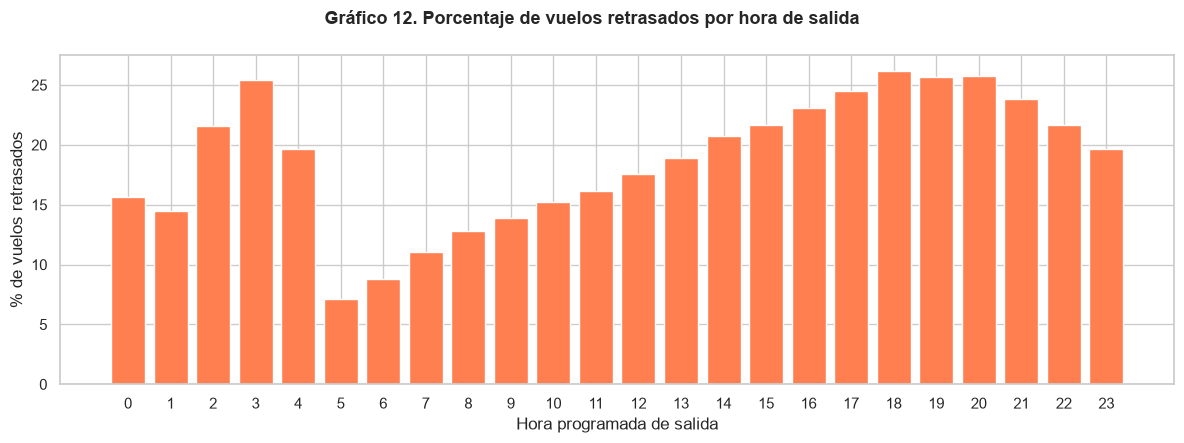

Entre las 5:00 y las 23:00, el menor retraso es a las 5:00 (7.1%) y el mayor a las 18:00 (26.2%).
Las horas de 0:00 a 4:00 tienen solo el 0.43% de los vuelos (vuelos nocturnos), por eso su porcentaje es más inestable.


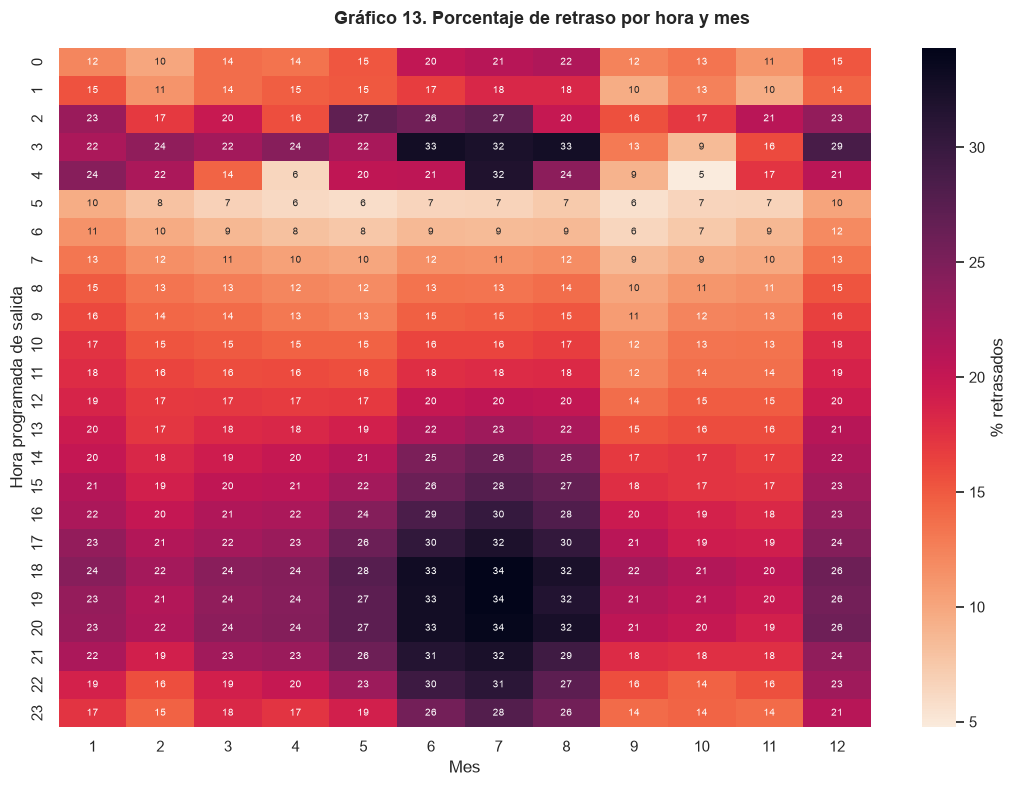

In [20]:
def tasa(por):
    return op.groupby(por, observed=True)["RETRASADO"].agg(tasa="mean", vuelos="size").assign(tasa=lambda t: t["tasa"] * 100)

t_hora = tasa("HORA_SALIDA")
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(t_hora.index, t_hora["tasa"], color="coral")
ax.set(xlabel="Hora programada de salida", ylabel="% de vuelos retrasados", xticks=range(24))
grafico(fig, "Porcentaje de vuelos retrasados por hora de salida")
dia = t_hora.loc[5:23]
print(f"Entre las 5:00 y las 23:00, el menor retraso es a las {dia['tasa'].idxmin()}:00 ({dia['tasa'].min():.1f}%) "
      f"y el mayor a las {dia['tasa'].idxmax()}:00 ({dia['tasa'].max():.1f}%).")
print(f"Las horas de 0:00 a 4:00 tienen solo el {t_hora.loc[0:4, 'vuelos'].sum() / t_hora['vuelos'].sum():.2%} "
      "de los vuelos (vuelos nocturnos), por eso su porcentaje es más inestable.")

hm = (op.groupby(["HORA_SALIDA", "MES"], observed=True)["RETRASADO"].mean() * 100).unstack()
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(hm, cmap="rocket_r", annot=True, fmt=".0f", annot_kws={"size": 7},
            cbar_kws={"label": "% retrasados"}, ax=ax)
ax.set(xlabel="Mes", ylabel="Hora programada de salida")
grafico(fig, "Porcentaje de retraso por hora y mes")

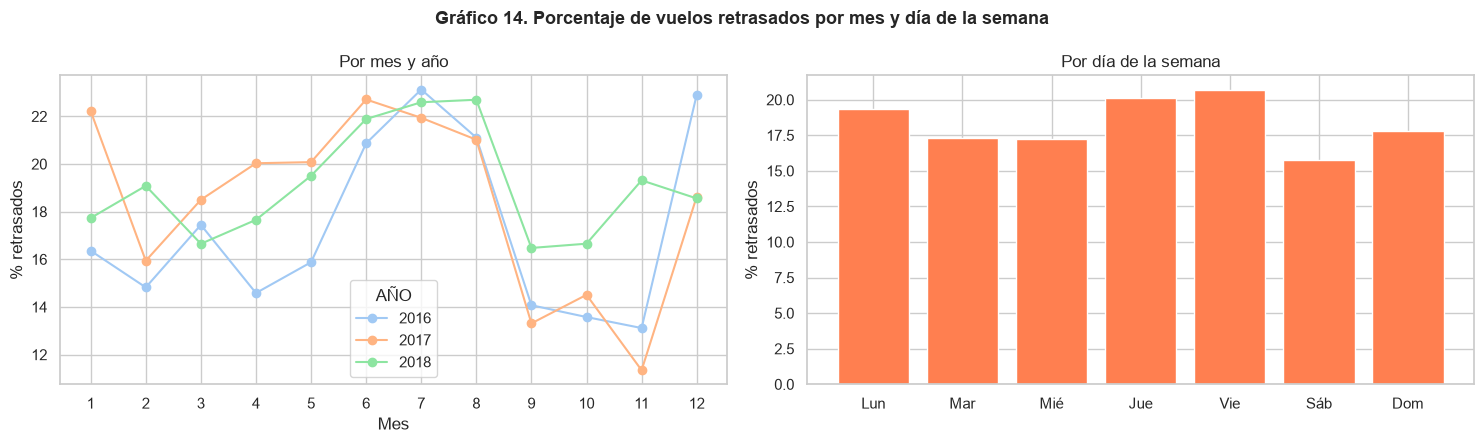

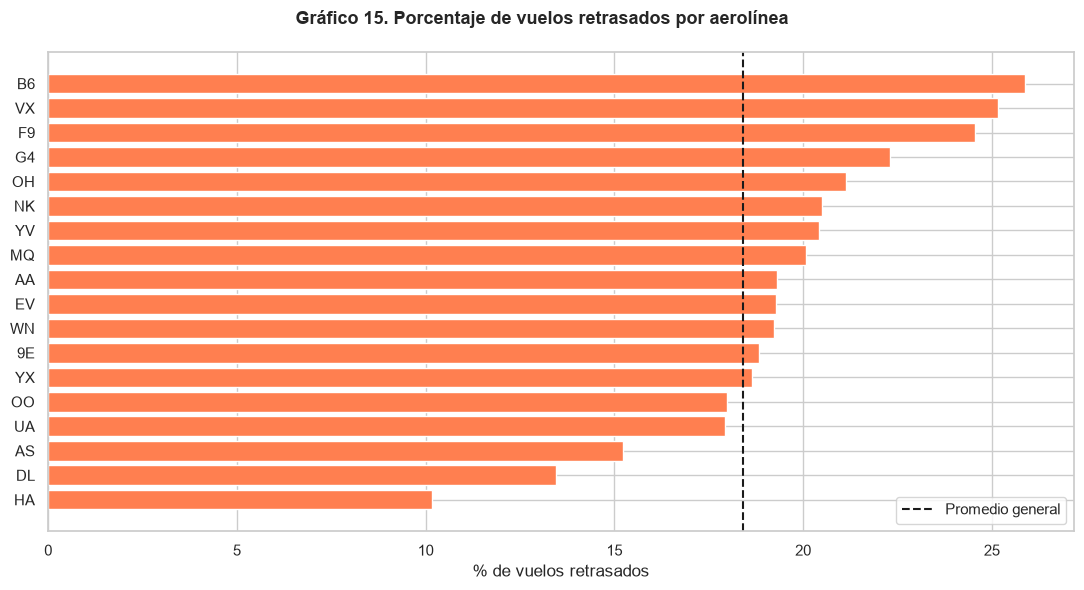

Aerolínea más puntual: HA (10.2%). Menos puntual: B6 (25.9%).


In [21]:
t_mes = (op.groupby(["AÑO", "MES"], observed=True)["RETRASADO"].mean() * 100).unstack("AÑO")
t_dia = tasa("DIA_SEMANA").rename(index=NOMBRE_DIA)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
t_mes.plot(marker="o", ax=ax[0]); ax[0].set(title="Por mes y año", xlabel="Mes", ylabel="% retrasados", xticks=range(1, 13))
ax[1].bar(t_dia.index, t_dia["tasa"], color="coral"); ax[1].set(title="Por día de la semana", ylabel="% retrasados")
grafico(fig, "Porcentaje de vuelos retrasados por mes y día de la semana")

t_aer = tasa("OP_CARRIER").query("vuelos > 10000").sort_values("tasa")
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(t_aer.index.astype(str), t_aer["tasa"], color="coral")
ax.axvline(op["RETRASADO"].mean() * 100, ls="--", c="k", label="Promedio general"); ax.legend()
ax.set_xlabel("% de vuelos retrasados")
grafico(fig, "Porcentaje de vuelos retrasados por aerolínea")
print(f"Aerolínea más puntual: {t_aer.index[0]} ({t_aer['tasa'].iloc[0]:.1f}%). "
      f"Menos puntual: {t_aer.index[-1]} ({t_aer['tasa'].iloc[-1]:.1f}%).")

### Cambio en las aerolíneas que reportan en 2018

En 2018 el número de vuelos sube cerca de 25 %. Antes de leerlo como crecimiento del tráfico hay que revisar **qué aerolíneas reportan cada año**: si en 2018 entran aerolíneas nuevas al reporte del DOT, el aumento (y parte del cambio en la tasa de retraso) se debe a la composición de la base y no al comportamiento de los vuelos.

In [22]:
rep_anio = df.pivot_table(index="OP_CARRIER", columns="AÑO", values="FL_DATE", aggfunc="size", observed=True).fillna(0).astype(int)
nuevas = rep_anio.index[(rep_anio.drop(columns=rep_anio.columns[-1]) == 0).all(axis=1)].tolist()
salen = rep_anio.index[rep_anio[rep_anio.columns[-1]] == 0].tolist()
tabla(rep_anio.sort_values(rep_anio.columns[-1], ascending=False), "Vuelos por aerolínea y año")

comunes = rep_anio.index[(rep_anio > 0).all(axis=1)]
t_todas = op.groupby("AÑO")["RETRASADO"].mean() * 100
t_comunes = op[op["OP_CARRIER"].isin(comunes)].groupby("AÑO")["RETRASADO"].mean() * 100
comp_anio = pd.DataFrame({"vuelos": df.groupby("AÑO").size(),
                          "% retraso (todas)": t_todas.round(2),
                          "% retraso (solo aerolíneas presentes los 3 años)": t_comunes.round(2)})
tabla(comp_anio, "Tendencia anual con y sin las aerolíneas nuevas")
HALLAZGOS["aerolineas_nuevas_ultimo_anio"] = nuevas
HALLAZGOS["tendencia_comparable"] = t_comunes.round(2).to_dict()
print(f"Aerolíneas que solo aparecen en {rep_anio.columns[-1]}: {nuevas}")
print(f"Aerolíneas que dejan de aparecer: {salen if salen else 'ninguna'}")
print("Para hablar de tendencia entre años se debe usar la columna de aerolíneas presentes los 3 años.")

Tabla 9. Vuelos por aerolínea y año


AÑO,2016,2017,2018
OP_CARRIER,,,
WN,1299433,1329432,1352528
DL,922744,923548,949281
AA,914483,896337,916802
OO,605883,706484,774079
UA,545064,584480,621556
YX,0,0,316077
B6,282471,298653,305006
MQ,0,0,295981
OH,0,0,278428


Tabla 10. Tendencia anual con y sin las aerolíneas nuevas


,vuelos,% retraso (todas),% retraso (solo aerolíneas presentes los 3 años)
AÑO,,,
2016,5617534,17.41,17.41
2017,5674495,18.45,18.45
2018,7206035,19.12,18.92


Aerolíneas que solo aparecen en 2018: ['9E', 'G4', 'MQ', 'OH', 'YV', 'YX']
Aerolíneas que dejan de aparecer: ninguna
Para hablar de tendencia entre años se debe usar la columna de aerolíneas presentes los 3 años.


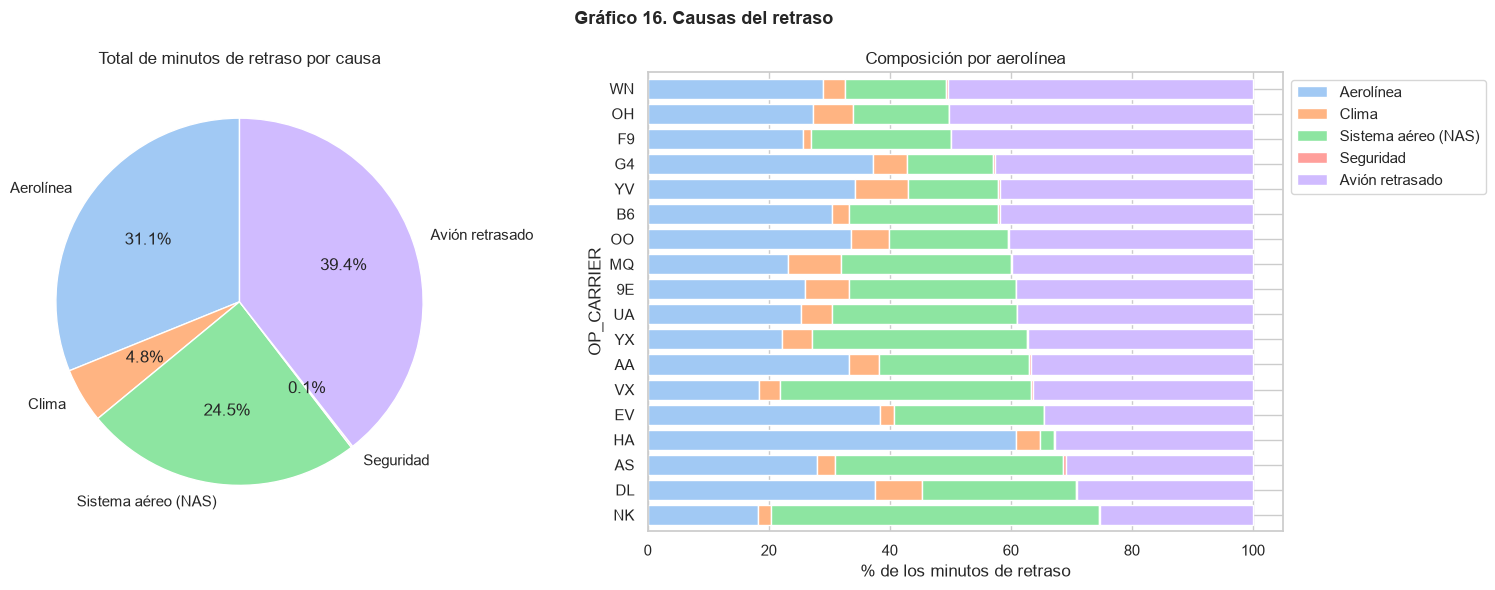

Porcentaje de minutos de retraso por causa:
 Aerolínea             31.10
Clima                  4.80
Sistema aéreo (NAS)   24.50
Seguridad              0.10
Avión retrasado       39.40


In [23]:
# Composición de los minutos de retraso por causa
minutos = op[CAUSAS].sum()
minutos.index = ["Aerolínea", "Clima", "Sistema aéreo (NAS)", "Seguridad", "Avión retrasado"]
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ax[0].pie(minutos, labels=minutos.index, autopct="%1.1f%%", startangle=90,
          colors=sns.color_palette("pastel", 5))
ax[0].set_title("Total de minutos de retraso por causa")
comp = op.groupby("OP_CARRIER", observed=True)[CAUSAS].sum()
comp = comp[op["OP_CARRIER"].value_counts().loc[comp.index] > 10000]
comp = comp.div(comp.sum(axis=1), axis=0) * 100
comp.columns = minutos.index
comp.sort_values("Avión retrasado").plot.barh(stacked=True, ax=ax[1], color=sns.color_palette("pastel", 5), width=0.8)
ax[1].set_xlabel("% de los minutos de retraso"); ax[1].legend(bbox_to_anchor=(1, 1))
ax[1].set_title("Composición por aerolínea")
grafico(fig, "Causas del retraso")
pct = minutos / minutos.sum() * 100
HALLAZGOS["pct_minutos_por_causa"] = pct.round(1).to_dict()
print("Porcentaje de minutos de retraso por causa:\n", pct.round(1).to_string())

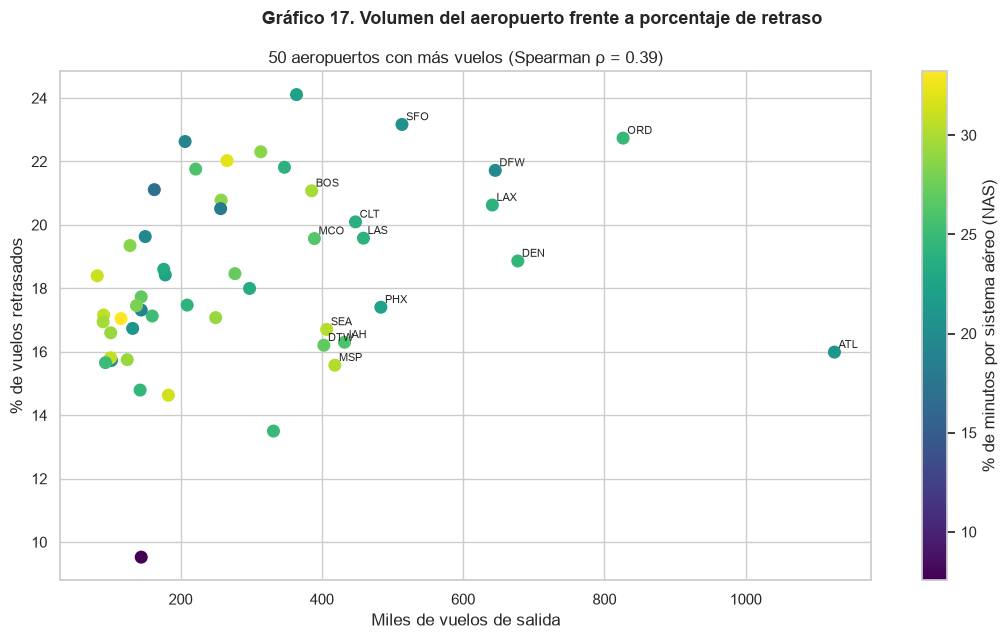

In [24]:
t_ori = tasa("ORIGIN").nlargest(50, "vuelos")
nas = op.groupby("ORIGIN", observed=True)[CAUSAS].sum()
t_ori["pct_NAS"] = (nas["NAS_DELAY"] / nas.sum(axis=1) * 100).loc[t_ori.index]
rho_ap = t_ori["vuelos"].corr(t_ori["tasa"], method="spearman")
fig, ax = plt.subplots(figsize=(11, 6.5))
sc = ax.scatter(t_ori["vuelos"] / 1e3, t_ori["tasa"], c=t_ori["pct_NAS"], cmap="viridis", s=70)
for cod, r in t_ori.head(15).iterrows():
    ax.annotate(str(cod), (r["vuelos"] / 1e3, r["tasa"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
plt.colorbar(sc, label="% de minutos por sistema aéreo (NAS)")
ax.set(xlabel="Miles de vuelos de salida", ylabel="% de vuelos retrasados",
       title=f"50 aeropuertos con más vuelos (Spearman ρ = {rho_ap:.2f})")
grafico(fig, "Volumen del aeropuerto frente a porcentaje de retraso")

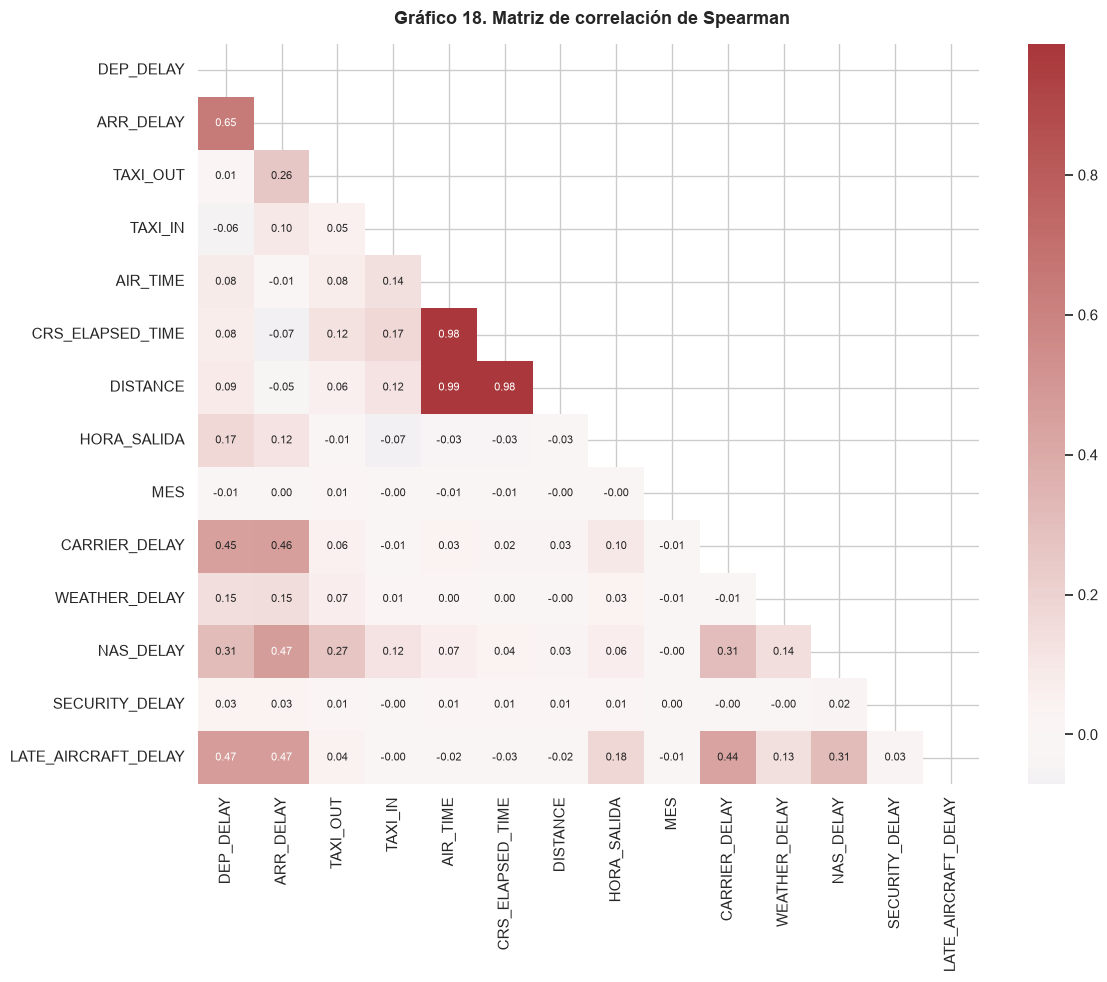

Correlación DEP_DELAY - ARR_DELAY: 0.65 (alta). El retraso de llegada se explica en buena parte por el de salida, pero DEP_DELAY no se conoce antes del vuelo y no debe usarse para predecir (fuga de información).


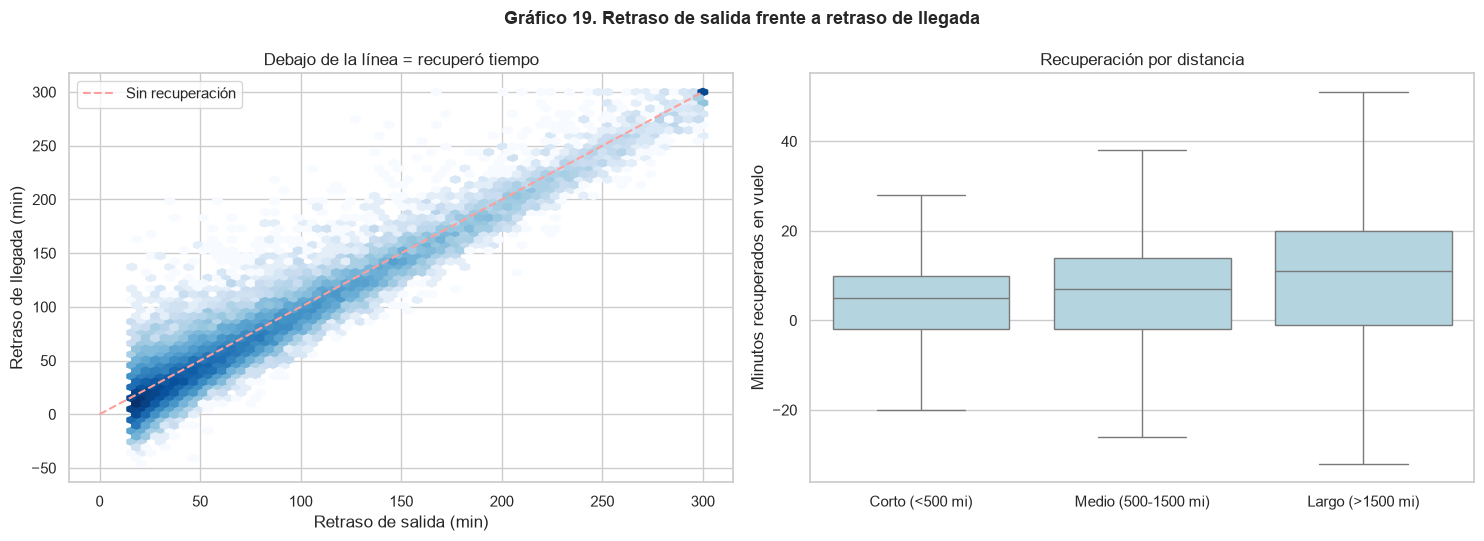

In [25]:
m = op.sample(min(N_MUESTRA_GRAF, len(op)), random_state=SEED)
corr = m[["DEP_DELAY", "ARR_DELAY", "TAXI_OUT", "TAXI_IN", "AIR_TIME", "CRS_ELAPSED_TIME",
          "DISTANCE", "HORA_SALIDA", "MES"] + CAUSAS].astype("float64").corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)), cmap="vlag", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax)
grafico(fig, "Matriz de correlación de Spearman")
r_dep = corr.loc["DEP_DELAY", "ARR_DELAY"]
HALLAZGOS["spearman_dep_arr"] = round(float(r_dep), 2)
print(f"Correlación DEP_DELAY - ARR_DELAY: {r_dep:.2f} ({'muy alta' if r_dep > 0.8 else 'alta' if r_dep > 0.6 else 'moderada'}). "
      "El retraso de llegada se explica en buena parte por el de salida, pero DEP_DELAY no se conoce "
      "antes del vuelo y no debe usarse para predecir (fuga de información).")

d = m[m["DEP_DELAY"] > UMBRAL_RETRASO].assign(RECUPERACION=lambda x: x["DEP_DELAY"] - x["ARR_DELAY"])
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
lim = d[["DEP_DELAY", "ARR_DELAY"]].clip(upper=300)
hb = ax[0].hexbin(lim["DEP_DELAY"], lim["ARR_DELAY"], gridsize=60, bins="log", cmap="Blues")
ax[0].plot([0, 300], [0, 300], "r--", label="Sin recuperación"); ax[0].legend()
ax[0].set(xlabel="Retraso de salida (min)", ylabel="Retraso de llegada (min)", title="Debajo de la línea = recuperó tiempo")
sns.boxplot(data=d, x="SEG_DISTANCIA", y="RECUPERACION", showfliers=False, ax=ax[1], color="lightblue")
ax[1].set(xlabel="", ylabel="Minutos recuperados en vuelo", title="Recuperación por distancia")
grafico(fig, "Retraso de salida frente a retraso de llegada")

In [26]:
def cramers_v(x, y):
    """V de Cramér con corrección de sesgo (Bergsma, 2013). 0 = sin asociación, 1 = asociación total."""
    t = pd.crosstab(x, y).to_numpy(); n = t.sum()
    esperado = np.outer(t.sum(axis=1), t.sum(axis=0)) / n
    chi2 = ((t - esperado) ** 2 / esperado).sum()
    r, k = t.shape
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2 / max(1e-12, min(kc - 1, rc - 1))))

asoc = pd.Series({v: cramers_v(m["RETRASADO"], m[v]) for v in
                  ["HORA_SALIDA", "MES", "OP_CARRIER", "ORIGIN", "DIA_SEMANA", "SEG_DISTANCIA", "AÑO"]},
                 name="V de Cramér").sort_values(ascending=False)
tabla(asoc.round(3).to_frame(), "Fuerza de asociación de cada variable con RETRASADO")
print("Con millones de filas el p-valor del chi-cuadrado siempre es significativo; por eso se usa la V de Cramér "
      "para comparar la fuerza de la asociación. Referencia: < 0,1 débil, 0,1-0,3 moderada, > 0,3 fuerte.")

tabla(pd.crosstab(m["SEG_DISTANCIA"], m["RETRASADO"].map({0: "A tiempo", 1: "Retrasado"}), normalize="index")
      .mul(100).round(1), "Tabla de contingencia: distancia frente a retraso (% por fila)")

Tabla 11. Fuerza de asociación de cada variable con RETRASADO


,V de Cramér
HORA_SALIDA,0.15
OP_CARRIER,0.08
ORIGIN,0.08
MES,0.07
DIA_SEMANA,0.04
AÑO,0.02
SEG_DISTANCIA,0.01


Con millones de filas el p-valor del chi-cuadrado siempre es significativo; por eso se usa la V de Cramér para comparar la fuerza de la asociación. Referencia: < 0,1 débil, 0,1-0,3 moderada, > 0,3 fuerte.
Tabla 12. Tabla de contingencia: distancia frente a retraso (% por fila)


RETRASADO,A tiempo,Retrasado
SEG_DISTANCIA,,
Corto (<500 mi),82.20,17.80
Medio (500-1500 mi),81.30,18.70
Largo (>1500 mi),80.90,19.10


## 9. Validación de hipótesis

| # | Hipótesis | Criterio |
|---|---|---|
| H1 | **Efecto cascada:** el retraso se acumula durante el día | La tasa de la noche (17–21 h) supera a la de la mañana (5–9 h) y el peso de "avión retrasado" crece en la tarde |
| H2 | **Estacionalidad:** junio, julio y diciembre tienen más retraso | Esos meses están entre los 4 más altos en cada año |
| H3 | **Congestión:** a más vuelos en el aeropuerto, más retraso | Spearman ρ > 0,3 entre volumen y tasa (50 aeropuertos más grandes) |
| H4 | **Retraso controlable:** aerolínea + avión retrasado explican más de la mitad de los minutos | Esa suma supera el 50 % |
| H5 | **Recuperación en vuelo:** los vuelos largos recuperan más minutos | La mediana recuperada en vuelos largos supera en 5 min o más a la de los cortos |

In [27]:
res = []

# H1
man, noc = t_hora.loc[5:9, "tasa"].mean(), t_hora.loc[17:21, "tasa"].mean()
ret = op[op["RETRASADO"] == 1]
la = ret.groupby("HORA_SALIDA")[CAUSAS].sum()
la = la["LATE_AIRCRAFT_DELAY"] / la.sum(axis=1) * 100
la_man, la_noc = la.loc[5:9].mean(), la.loc[17:21].mean()
res.append(["H1", f"Mañana {man:.1f}% vs. noche {noc:.1f}%; avión retrasado {la_man:.1f}% vs. {la_noc:.1f}% de los minutos",
            "Se acepta" if (noc > man and la_noc > la_man) else ("Parcial" if noc > man else "Se rechaza")])

# H2
top4 = {a: set(t_mes[a].nlargest(4).index) for a in t_mes.columns}
cumple = sum({6, 7, 12} <= s or len({6, 7, 12} & s) >= 2 for s in top4.values())
res.append(["H2", "; ".join(f"{a}: meses más altos {sorted(s)}" for a, s in top4.items()),
            "Se acepta" if cumple == len(top4) else ("Parcial" if cumple else "Se rechaza")])

# H3
res.append(["H3", f"Spearman ρ volumen-retraso = {rho_ap:.2f}",
            "Se acepta" if rho_ap > 0.3 else "Se rechaza"])

# H4
ctrl = pct["Aerolínea"] + pct["Avión retrasado"]
res.append(["H4", f"Aerolínea + avión retrasado = {ctrl:.1f}% de los minutos",
            "Se acepta" if ctrl > 50 else "Se rechaza"])

# H5
rec = d.groupby("SEG_DISTANCIA", observed=True)["RECUPERACION"].median()
dif = rec.iloc[-1] - rec.iloc[0]
res.append(["H5", "Mediana recuperada: " + ", ".join(f"{k} {v:.0f} min" for k, v in rec.items()),
            "Se acepta" if dif >= 5 else "Se rechaza"])

hip = pd.DataFrame(res, columns=["Hipótesis", "Evidencia", "Resultado"]).set_index("Hipótesis")
tabla(hip, "Resultado de la validación de hipótesis")
HALLAZGOS["hipotesis"] = hip["Resultado"].to_dict()

Tabla 13. Resultado de la validación de hipótesis


,Evidencia,Resultado
Hipótesis,,
H1,Mañana 10.7% vs. noche 25.2%; avión retrasado ...,Se acepta
H2,"2016: meses más altos [6, 7, 8, 12]; 2017: mes...",Se acepta
H3,Spearman ρ volumen-retraso = 0.39,Se acepta
H4,Aerolínea + avión retrasado = 70.6% de los min...,Se acepta
H5,"Mediana recuperada: Corto (<500 mi) 5 min, Med...",Se acepta


## 10. Resumen de hallazgos

Se guardan los números clave en `salidas_eda/hallazgos_eda.json` y las tablas agregadas que luego se suben a AWS (no se sube la base original).
Con estos archivos y los gráficos numerados se redacta la sección de EDA del informe.

In [28]:
# Tablas agregadas para AWS y Grafana
agg_cols = dict(vuelos=("RETRASADO", "size"), retrasados=("RETRASADO", "sum"),
                **{f"min_{c}": (c, "sum") for c in CAUSAS})
for nombre, por in {"anio_mes": ["AÑO", "MES"], "aerolinea_anio": ["OP_CARRIER", "AÑO"],
                    "aeropuerto": ["ORIGIN"], "hora_mes": ["HORA_SALIDA", "MES"]}.items():
    t = op.groupby(por, observed=True).agg(**agg_cols)
    t["tasa_retraso"] = t["retrasados"] / t["vuelos"]
    t.to_csv(OUT_DIR / f"agg_{nombre}.csv")
canc_agg = df.groupby(["AÑO", "MES", "CAUSA_CANCELACION"], observed=True).size().rename("vuelos")
canc_agg.to_csv(OUT_DIR / "agg_cancelaciones.csv")

with open(OUT_DIR / "hallazgos_eda.json", "w", encoding="utf-8") as f:
    json.dump(HALLAZGOS, f, ensure_ascii=False, indent=2, default=str)

print(json.dumps(HALLAZGOS, ensure_ascii=False, indent=2, default=str))
print(f"\n{_cont['grafico']} gráficos y {_cont['tabla']} tablas guardados en {OUT_DIR.resolve()}")

{
  "tamano_gb": 2.13,
  "filas": 18505725,
  "columnas": 28,
  "duplicados_eliminados": 11,
  "arr_delay_media": 4.4,
  "arr_delay_mediana": -6.0,
  "arr_delay_p95": 70.0,
  "hora_pico_vuelos": 6,
  "aerolinea_mas_vuelos": "WN",
  "top25_aeropuertos_pct": 61.6,
  "causa_cancelacion_principal": "Clima",
  "tasa_retraso": 18.39,
  "tasa_cancelacion": 1.43,
  "tasa_desvio": 0.24,
  "aerolineas_nuevas_ultimo_anio": [
    "9E",
    "G4",
    "MQ",
    "OH",
    "YV",
    "YX"
  ],
  "tendencia_comparable": {
    "2016": 17.41,
    "2017": 18.45,
    "2018": 18.92
  },
  "pct_minutos_por_causa": {
    "Aerolínea": 31.100000381469727,
    "Clima": 4.800000190734863,
    "Sistema aéreo (NAS)": 24.5,
    "Seguridad": 0.10000000149011612,
    "Avión retrasado": 39.400001525878906
  },
  "spearman_dep_arr": 0.65,
  "hipotesis": {
    "H1": "Se acepta",
    "H2": "Se acepta",
    "H3": "Se acepta",
    "H4": "Se acepta",
    "H5": "Se acepta"
  }
}

19 gráficos y 13 tablas guardados en C:\Users\U